# Задание 4: сравнение экспериментов и каталог submission

Исходный `task4.ipynb` и первый `task4_data/task4_submission.csv` сохранены. Семь отдельных исследовательских
ноутбуков содержат модели, обучение и реальные результаты. Этот notebook собирает их в одну таблицу;
он ничего не обучает и не отправляет на Kaggle. Сводные числа лежат в `task4_data/experiment_catalog.json`.

**Что улучшилось.** В исходной сети переобучение начиналось уже после нескольких эпох. Сильнее dropout,
BatchNorm и weight decay дали устойчивое улучшение. Дополнительный выигрыш принесла вероятностная голова:
сеть предсказывает распределение по 91 значению года, а итоговый прогноз — его среднее. Цель обучения
для основного семейства: MSE нормированного года + 2×cross-entropy с мягкой меткой σ=0.6 года.
Это одна сеть; усреднения прогнозов разных моделей, ансамблей, внешних данных и pretrained-весов нет.

Вариант `meansnorm` дополнительно нормирует первые 12 стандартизованных признаков на их RMS и сохраняет
логарифм этого RMS отдельным 91-м признаком. `meansquad` добавляет 78 квадратов/парных произведений
первых 12 признаков (после ограничения ±5), получая 168 признаков. Все параметры преобразований обучены только на train.

**Граница уверенности.** Средняя validation MSE улучшилась с 83.5600 до 78.3971 (6.18%), но три разбиения
участвовали в поиске. Лидер валидации `meansquad` не стал лидером контрольной проверки; перенос его
дополнительного выигрыша не подтверждён. Лучший контрольный результат `meansnorm` —80.7900 против 87.0897
исходной сети, однако выбирать по этому минимуму как по совершенно независимому тесту нельзя.
Окончательные public/private scores новых CSV пока неизвестны. Значительное улучшение Kaggle не гарантируется.

In [1]:
from pathlib import Path
import hashlib
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd()/"homeworks").is_dir() else Path.cwd().parent
DATA_DIR = ROOT/"homeworks"/"task4_data"
catalog = json.loads((DATA_DIR/"experiment_catalog.json").read_text())
meta = catalog["metadata"]
submissions = catalog["submissions"]
assert hashlib.sha256((ROOT/"homeworks"/"task4.ipynb").read_bytes()).hexdigest() == meta["baseline_notebook_sha256"]
print(f"Поисковых конфигураций по направлениям (включая контроли): {meta['configurations_total']}")
print(f"CSV: {meta['csv_files']}; различных наборов прогнозов: {meta['unique_csv_contents']}")
print(meta["protocol_note"])
display(pd.DataFrame(list(meta["family_configurations"].items()),columns=["Направление","Конфигураций"]))

Поисковых конфигураций по направлениям (включая контроли): 343
CSV: 25; различных наборов прогнозов: 24
Число конфигураций считается отдельно внутри каждого направления и включает контрольные модели; между направлениями есть повторения. Три validation-разбиения использовались для выбора. Audit открыт после заморозки новых конфигураций; исходный baseline оценивался на нём ранее. CSV обучены на 14000, audit-метрики относятся к checkpoint с 9800 train. Новые public/private scores неизвестны.


,Направление,Конфигураций
0,regularization,66
1,augmentation,32
2,preprocessing,76
3,objectives,92
4,embeddings,36
5,interactions,29
6,combined,12


## Первые загрузки на Kaggle

Сначала разумно загрузить четыре существенно различающихся кандидата: `combined_meansnorm`,
`bn_dist_pure_ce_p1`, `combined_meansquad`, `combined_standard`. Первый силён на контрольной выборке,
второй использует другую функцию потерь, третий выиграл по средней валидации, четвёртый служит
контролем без дополнительных признаков. Это порядок проверки, **не выбор окончательных двух submission**.
Простой MSE-вариант регуляризации указан пятым как резерв.

Не отправлять оба файла, отмеченные как точные дубликаты: их содержимое одинаково. Окончательные два
варианта стоит выбирать после сравнения полученных public scores с локальными результатами, учитывая,
что многократный отбор по public leaderboard тоже приводит к переобучению.

In [2]:
rows=[]
for r in submissions:
    rows.append({"Приоритет":r["upload_priority"],"ID":r["id"],"Notebook":r["notebook"],
                 "MSE mean validation":r["validation_mean_mse"],
                 "MSE audit":r["audit"]["mse"] if r["audit"] else None,
                 "Эпохи refit":r["epochs"],"CSV":r["file"],"Дубликат":r["duplicate_of"]})
table=pd.DataFrame(rows)
priority=table[table["Приоритет"].notna()].sort_values("Приоритет")
display(priority[["Приоритет","ID","MSE mean validation","MSE audit","Эпохи refit"]].round(4))
for r in sorted([r for r in submissions if r["upload_priority"]],key=lambda r:r["upload_priority"]):
    display(Markdown(f"{r['upload_priority']}. [{r['id']}](task4_data/Submission/{Path(r['file']).name}) — [{Path(r['notebook']).name}]({Path(r['notebook']).name})"))

,Приоритет,ID,MSE mean validation,MSE audit,Эпохи refit
1,1.0,combined_meansnorm,78.6870,80.7900,33
6,2.0,bn_dist_pure_ce_p1,78.9341,81.5518,23
0,3.0,combined_meansquad,78.3971,83.6913,30
3,4.0,combined_standard,78.7574,82.8207,31
9,5.0,bn128_d55_wd0.5,80.4038,82.3692,31


1. [combined_meansnorm](task4_data/Submission/task4_combined_meansnorm.csv) — [task4_combined.ipynb](task4_combined.ipynb)

2. [bn_dist_pure_ce_p1](task4_data/Submission/task4_objectives_bn_dist_pure_ce_p1.csv) — [task4_objectives.ipynb](task4_objectives.ipynb)

3. [combined_meansquad](task4_data/Submission/task4_combined_meansquad.csv) — [task4_combined.ipynb](task4_combined.ipynb)

4. [combined_standard](task4_data/Submission/task4_combined_standard.csv) — [task4_combined.ipynb](task4_combined.ipynb)

5. [bn128_d55_wd0.5](task4_data/Submission/task4_regularization_bn128_d55_wd0.5.csv) — [task4_regularization.ipynb](task4_regularization.ipynb)

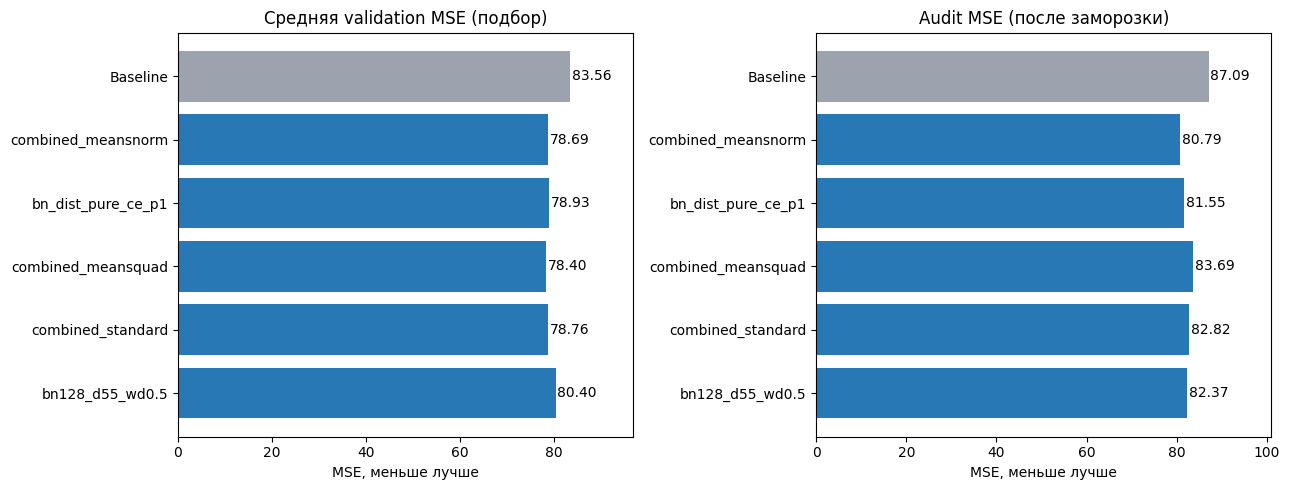

In [3]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
short=priority.sort_values("Приоритет")
labels=["Baseline"]+short["ID"].tolist()
validation=[meta["baseline"]["validation_mean_mse"]]+short["MSE mean validation"].tolist()
audit=[meta["baseline"]["audit_mse"]]+short["MSE audit"].tolist()
for ax,values,title in zip(axes,[validation,audit],["Средняя validation MSE (подбор)","Audit MSE (после заморозки)"]):
    ax.barh(labels,values,color=["#9ca3af"]+["#2878b5"]*len(short))
    ax.invert_yaxis();ax.set(xlabel="MSE, меньше лучше",title=title,xlim=(0,max(values)*1.16))
    for i,value in enumerate(values):ax.text(value+.4,i,f"{value:.2f}",va="center")
fig.tight_layout()
plt.show()

## Полный список вариантов

MSE audit отсутствует у вариантов, не включённых в заранее замороженную контрольную проверку.
Все CSV сформированы одной моделью после refit на 14000 размеченных строках. Validation/audit оценки
получены до этого refit и не являются измеренной ошибкой финальной модели на скрытом тесте.

In [4]:
display(table.sort_values("MSE mean validation").round(5))
expected_ids=pd.read_csv(DATA_DIR/"test_x.csv",usecols=["id"])["id"]
for r in submissions:
    path=ROOT/r["file"]
    assert hashlib.sha256(path.read_bytes()).hexdigest()==r["sha256"],r["id"]
    frame=pd.read_csv(path)
    assert list(frame.columns)==["id","year"] and len(frame)==6000,r["id"]
    assert frame["id"].equals(expected_ids) and frame["id"].is_unique,r["id"]
    assert np.isfinite(frame["year"]).all(),r["id"]
print(f"Проверены все{len(submissions)} CSV: hash,6000строк,id,порядок,finite years.")
for r in submissions:
    if r["duplicate_of"]:print("Дубликат:",r["file"],"=",r["duplicate_of"])

Проверены все25 CSV: hash,6000строк,id,порядок,finite years.
Дубликат: homeworks/task4_data/Submission/task4_objectives_reg55_wd1_s0.6_ce2.csv = homeworks/task4_data/Submission/task4_combined_standard.csv


,Приоритет,ID,Notebook,MSE mean validation,MSE audit,Эпохи refit,CSV,Дубликат
0,3.0,combined_meansquad,homeworks/task4_combined.ipynb,78.39712,83.69134,30,homeworks/task4_data/Submission/task4_combined...,NaN
1,1.0,combined_meansnorm,homeworks/task4_combined.ipynb,78.68696,80.78999,33,homeworks/task4_data/Submission/task4_combined...,NaN
2,NaN,reg55_wd1_s0.6_ce2,homeworks/task4_objectives.ipynb,78.75741,82.82066,31,homeworks/task4_data/Submission/task4_objectiv...,homeworks/task4_data/Submission/task4_combined...
3,4.0,combined_standard,homeworks/task4_combined.ipynb,78.75741,82.82066,31,homeworks/task4_data/Submission/task4_combined...,NaN
4,NaN,reg55_wd5_s0.25_ce2,homeworks/task4_objectives.ipynb,78.80469,83.24822,28,homeworks/task4_data/Submission/task4_objectiv...,NaN
5,NaN,reg55_wd1_s0.6_ce1,homeworks/task4_objectives.ipynb,78.81627,82.45350,28,homeworks/task4_data/Submission/task4_objectiv...,NaN
6,2.0,bn_dist_pure_ce_p1,homeworks/task4_objectives.ipynb,78.93415,81.55184,23,homeworks/task4_data/Submission/task4_objectiv...,NaN
7,NaN,bn_dist_s0.6_ce1,homeworks/task4_objectives.ipynb,79.37042,NaN,14,homeworks/task4_data/Submission/task4_objectiv...,NaN
8,NaN,strong_meansquad,homeworks/task4_preprocessing.ipynb,80.38219,82.59597,18,homeworks/task4_data/Submission/task4_preproce...,NaN
9,5.0,bn128_d55_wd0.5,homeworks/task4_regularization.ipynb,80.40381,82.36919,31,homeworks/task4_data/Submission/task4_regulari...,NaN


## Что не подтвердилось и что остаётся неизвестным

- PLE/RBF/периодические embeddings не превзошли свои простые MLP-контроли. Явные cross-слои также уступили контролю без них.
- Сильное нелинейное сжатие признаков чаще ухудшало результат. PCA оказался полезен для исходной residual-сети,
  но не дал устойчивого добавочного выигрыша поверх хорошо регуляризованной MLP.
- Mixup, input noise/masking, другие параметры Adam и размеры батча не улучшили сильный BN-контроль по среднему трёх разбиений.
- Квадратичные признаки улучшают среднюю валидацию вероятностной модели, но не контрольную оценку относительно standard.
  Нормирование первых 12 признаков с сохранением нормы выглядит более устойчивым кандидатом для внешней проверки.
- Local validation не воспроизводит в точности разделение Kaggle и не гарантирует разбиение по исполнителям.
  Контрольные 2100 строк не участвовали в нынешнем подборе, но исходный baseline на них уже оценивался ранее.
  После открытия новых audit-результатов архитектуры/потери/CSV не менялись.

Подробный воспроизводимый код — в семи исследовательских notebooks. Документация и ссылки на использованные
идеи приведены в них. Числа отражают фактические запуски; новых оценок Kaggle в этих результатах нет.

## Насколько убедительно улучшение на контрольных данных

Ниже — парный bootstrap разности MSE исходного baseline и зафиксированных моделей на одинаковых
2100 контрольных песнях. Положительное значение означает улучшение. Интервалы условны: предполагают
независимость песен и фиксированные модели, не учитывают весь поиск, общий исполнительский стиль и
прежнее использование audit исходным baseline. Приоритет загрузок уже учитывает эту диагностику,
поэтому не следует считать её полностью независимым подтверждением выбора.


In [5]:

import torch

audit_data=catalog["audit_predictions"]
target=torch.tensor(audit_data["target"],dtype=torch.float64)
prediction={name:torch.tensor(values,dtype=torch.float64) for name,values in audit_data["prediction"].items()}
base_error=(prediction["baseline"]-target).square()
names=["combined_meansnorm","bn_dist_pure_ce_p1","combined_meansquad","combined_standard"]
differences=torch.stack([base_error-(prediction[name]-target).square() for name in names])
generator=torch.Generator().manual_seed(2026)
boot=[]
for start in range(0,20000,200):
    indices=torch.randint(len(target),(min(200,20000-start),len(target)),generator=generator)
    boot.append(differences[:,indices].mean(-1))
boot=torch.cat(boot,dim=1)
interval=torch.quantile(boot,torch.tensor([.025,.975],dtype=torch.float64),dim=1)
uncertainty=[]
for i,name in enumerate(names):
    uncertainty.append({"ID":name,"Улучшение MSE":float(differences[i].mean()),
                        "95% lower":float(interval[0,i]),"95% upper":float(interval[1,i])})
display(pd.DataFrame(uncertainty).round(4))
# Сравнение первых двух кандидатов на тех же bootstrap-перевыборках.
gap=boot[0]-boot[1]
print("meansnorm − pureCE по улучшению MSE:",float((differences[0]-differences[1]).mean()),
      "; условный95%CI:",torch.quantile(gap,torch.tensor([.025,.975],dtype=torch.float64)).tolist())
print("Ни один этот интервал не гарантирует порядок моделей на private Kaggle test.")


meansnorm − pureCE по улучшению MSE: 0.76184873167248 ; условный95%CI: [-1.2176663736954692, 2.769118373385142]
Ни один этот интервал не гарантирует порядок моделей на private Kaggle test.


,ID,Улучшение MSE,95% lower,95% upper
0,combined_meansnorm,6.2997,3.4016,9.2236
1,bn_dist_pure_ce_p1,5.5379,2.7840,8.2731
2,combined_meansquad,3.3984,-0.0657,7.0057
3,combined_standard,4.2691,1.7303,6.7945
